In [91]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import linregress

plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams.update({"figure.dpi": 120, "font.size": 10,
                     "axes.titlesize": 12, "axes.labelsize": 10})

GW = ["GWETTOP", "GWETROOT", "GWETPROF"]
EXCLURE = ["YEAR", "DOY", "date", "site"]
VARIABLES_TENDANCE = ["T2M", "T2M_MAX", "T2M_MIN", "RH2M", "PRECTOTCORR"]

def afficher():
    plt.tight_layout()
    plt.show()


In [93]:
# Chargement unique : détecte automatiquement l'en-tête NASA POWER.
fichiers = {
    site: f"power_{site}_daily_1981_2025.csv"
    for site in ["abidjan", "bouake", "korhogo", "yamoussoukro"]
}

def charger_donnees(fichiers):
    dfs = {}
    for site, chemin in fichiers.items():
        with open(chemin, encoding="utf-8") as f:
            skip = next(i for i, ligne in enumerate(f) if ligne.startswith("YEAR"))
        d = pd.read_csv(chemin, skiprows=skip)
        print(site, "| valeurs -999 :", (d == -999).sum().loc[lambda x: x > 0].to_dict())
        d = d.replace(-999, np.nan)
        d["date"] = pd.to_datetime(d["YEAR"].astype(str), format="%Y") + pd.to_timedelta(d["DOY"] - 1, unit="D")
        dfs[site] = d.sort_values("date").reset_index(drop=True)
    return dfs, pd.concat([d.assign(site=site) for site, d in dfs.items()], ignore_index=True)

dfs, df_all = charger_donnees(fichiers)
cols = [c for c in dfs["abidjan"].columns if c not in EXCLURE]
print("Dimensions :", df_all.shape)


abidjan | valeurs -999 : {'ALLSKY_SFC_SW_DWN': 1095, 'CLRSKY_SFC_SW_DWN': 1095, 'ALLSKY_SFC_LW_DWN': 2556}
bouake | valeurs -999 : {'ALLSKY_SFC_SW_DWN': 1095, 'CLRSKY_SFC_SW_DWN': 1095, 'ALLSKY_SFC_LW_DWN': 2556}
korhogo | valeurs -999 : {'ALLSKY_SFC_SW_DWN': 1095, 'CLRSKY_SFC_SW_DWN': 1095, 'ALLSKY_SFC_LW_DWN': 2556}
yamoussoukro | valeurs -999 : {'ALLSKY_SFC_SW_DWN': 1095, 'CLRSKY_SFC_SW_DWN': 1095, 'ALLSKY_SFC_LW_DWN': 2556}
Dimensions : (65744, 22)


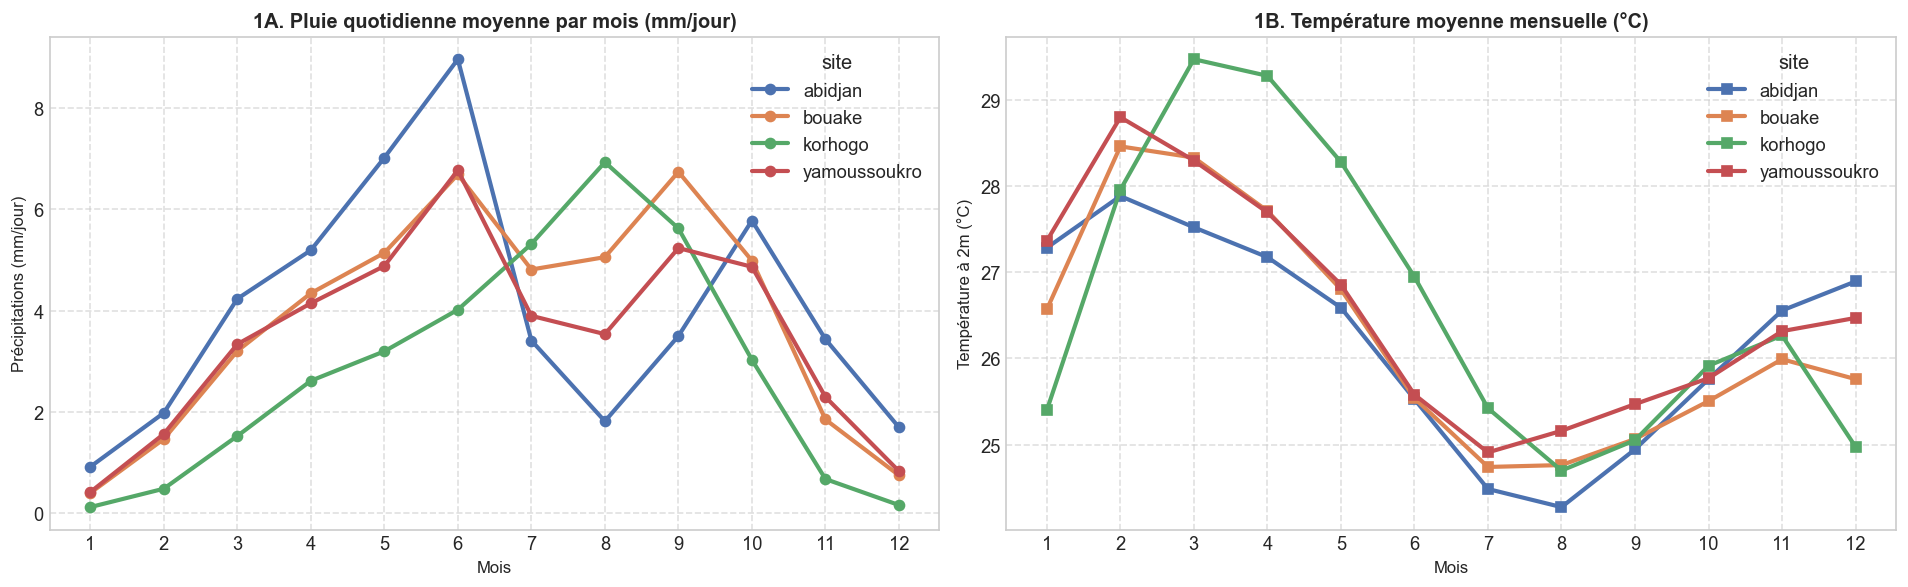

In [95]:
# ==============================================================================
# ÉTAPE 1 : CYCLE SAISONNIER (PRÉCIPITATIONS ET TEMPÉRATURES)
# ==============================================================================

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# 1. Précipitations mensuelles moyennes
pm = df_all.groupby(["site", df_all["date"].dt.month])["PRECTOTCORR"].mean().unstack(0)
pm.plot(ax=axes[0], marker="o", linewidth=2.5)
axes[0].set_title("1A. Pluie quotidienne moyenne par mois (mm/jour)", fontweight="bold")
axes[0].set_xlabel("Mois")
axes[0].set_ylabel("Précipitations (mm/jour)")
axes[0].set_xticks(range(1, 13))
axes[0].grid(True, linestyle="--", alpha=0.6)

# 2. Températures moyennes mensuelles
tm = df_all.groupby(["site", df_all["date"].dt.month])["T2M"].mean().unstack(0)
tm.plot(ax=axes[1], marker="s", linewidth=2.5)
axes[1].set_title("1B. Température moyenne mensuelle (°C)", fontweight="bold")
axes[1].set_xlabel("Mois")
axes[1].set_ylabel("Température à 2m (°C)")
axes[1].set_xticks(range(1, 13))
axes[1].grid(True, linestyle="--", alpha=0.6)

afficher()

C:\Users\BAHALA\AppData\Local\Temp\ipykernel_10132\3007069975.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_pluie, x="site", y="PRECTOTCORR", palette="Set2", ax=axes[0, 1])
C:\Users\BAHALA\AppData\Local\Temp\ipykernel_10132\3007069975.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_all, x="site", y="GWETTOP", palette="Pastel1", ax=axes[1, 1])


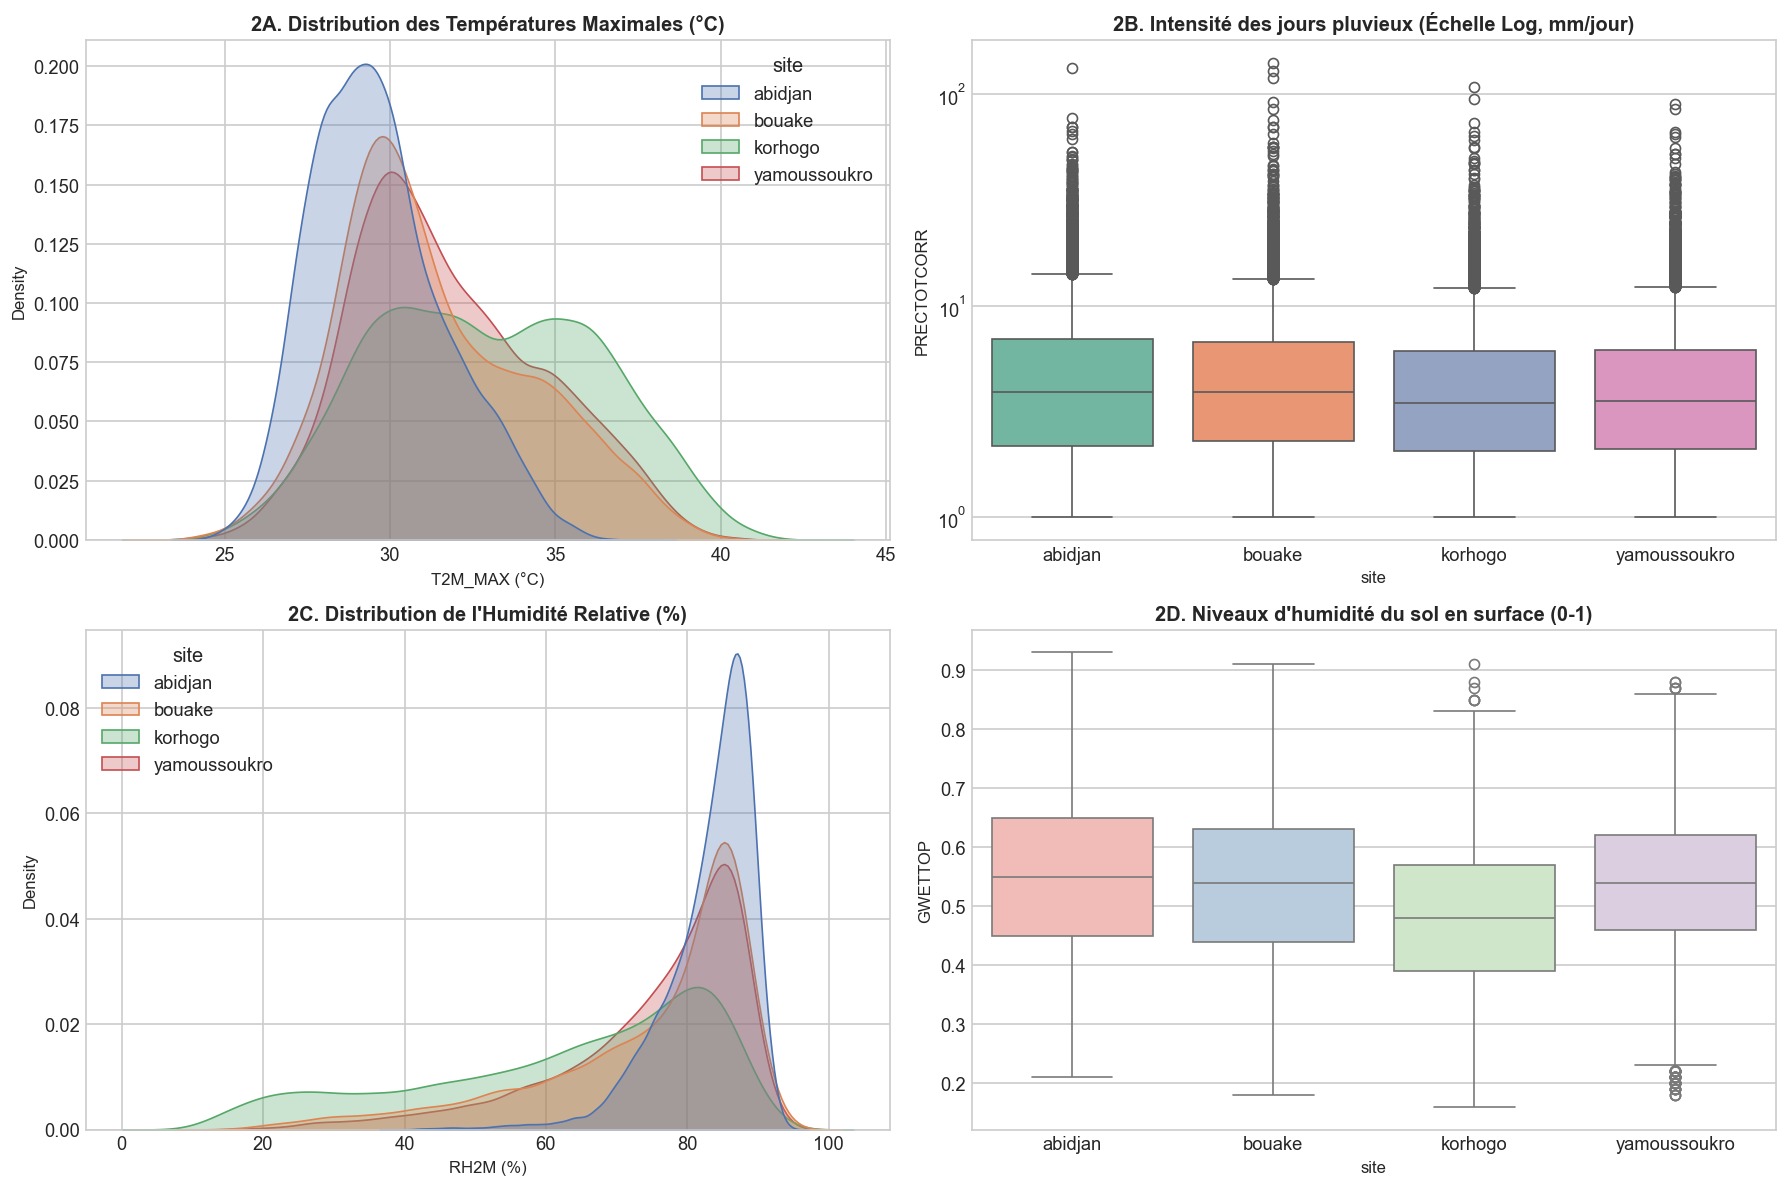

In [97]:
# ==============================================================================
# ÉTAPE 2 : DISTRIBUTIONS DES DENSITÉS ET DES BOÎTES À MOUSTACHES (BOXPLOTS)
# ==============================================================================

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 2A. Distribution de la Température Maximale (KDE)
sns.kdeplot(data=df_all, x="T2M_MAX", hue="site", common_norm=False, fill=True, alpha=0.3, ax=axes[0, 0])
axes[0, 0].set_title("2A. Distribution des Températures Maximales (°C)", fontweight="bold")
axes[0, 0].set_xlabel("T2M_MAX (°C)")

# 2B. Boxplot des Précipitations (sur les jours pluvieux >= 1mm)
df_pluie = df_all[df_all["PRECTOTCORR"] >= 1]
sns.boxplot(data=df_pluie, x="site", y="PRECTOTCORR", palette="Set2", ax=axes[0, 1])
axes[0, 1].set_yscale("log") # Échelle logarithmique pour mieux voir la queue des fortes pluies
axes[0, 1].set_title("2B. Intensité des jours pluvieux (Échelle Log, mm/jour)", fontweight="bold")

# 2C. Distribution de l'Humidité Relative
sns.kdeplot(data=df_all, x="RH2M", hue="site", common_norm=False, fill=True, alpha=0.3, ax=axes[1, 0])
axes[1, 0].set_title("2C. Distribution de l'Humidité Relative (%)", fontweight="bold")
axes[1, 0].set_xlabel("RH2M (%)")

# 2D. Boxplot de l'Humidité du sol en surface (GWETTOP)
sns.boxplot(data=df_all, x="site", y="GWETTOP", palette="Pastel1", ax=axes[1, 1])
axes[1, 1].set_title("2D. Niveaux d'humidité du sol en surface (0-1)", fontweight="bold")

afficher()

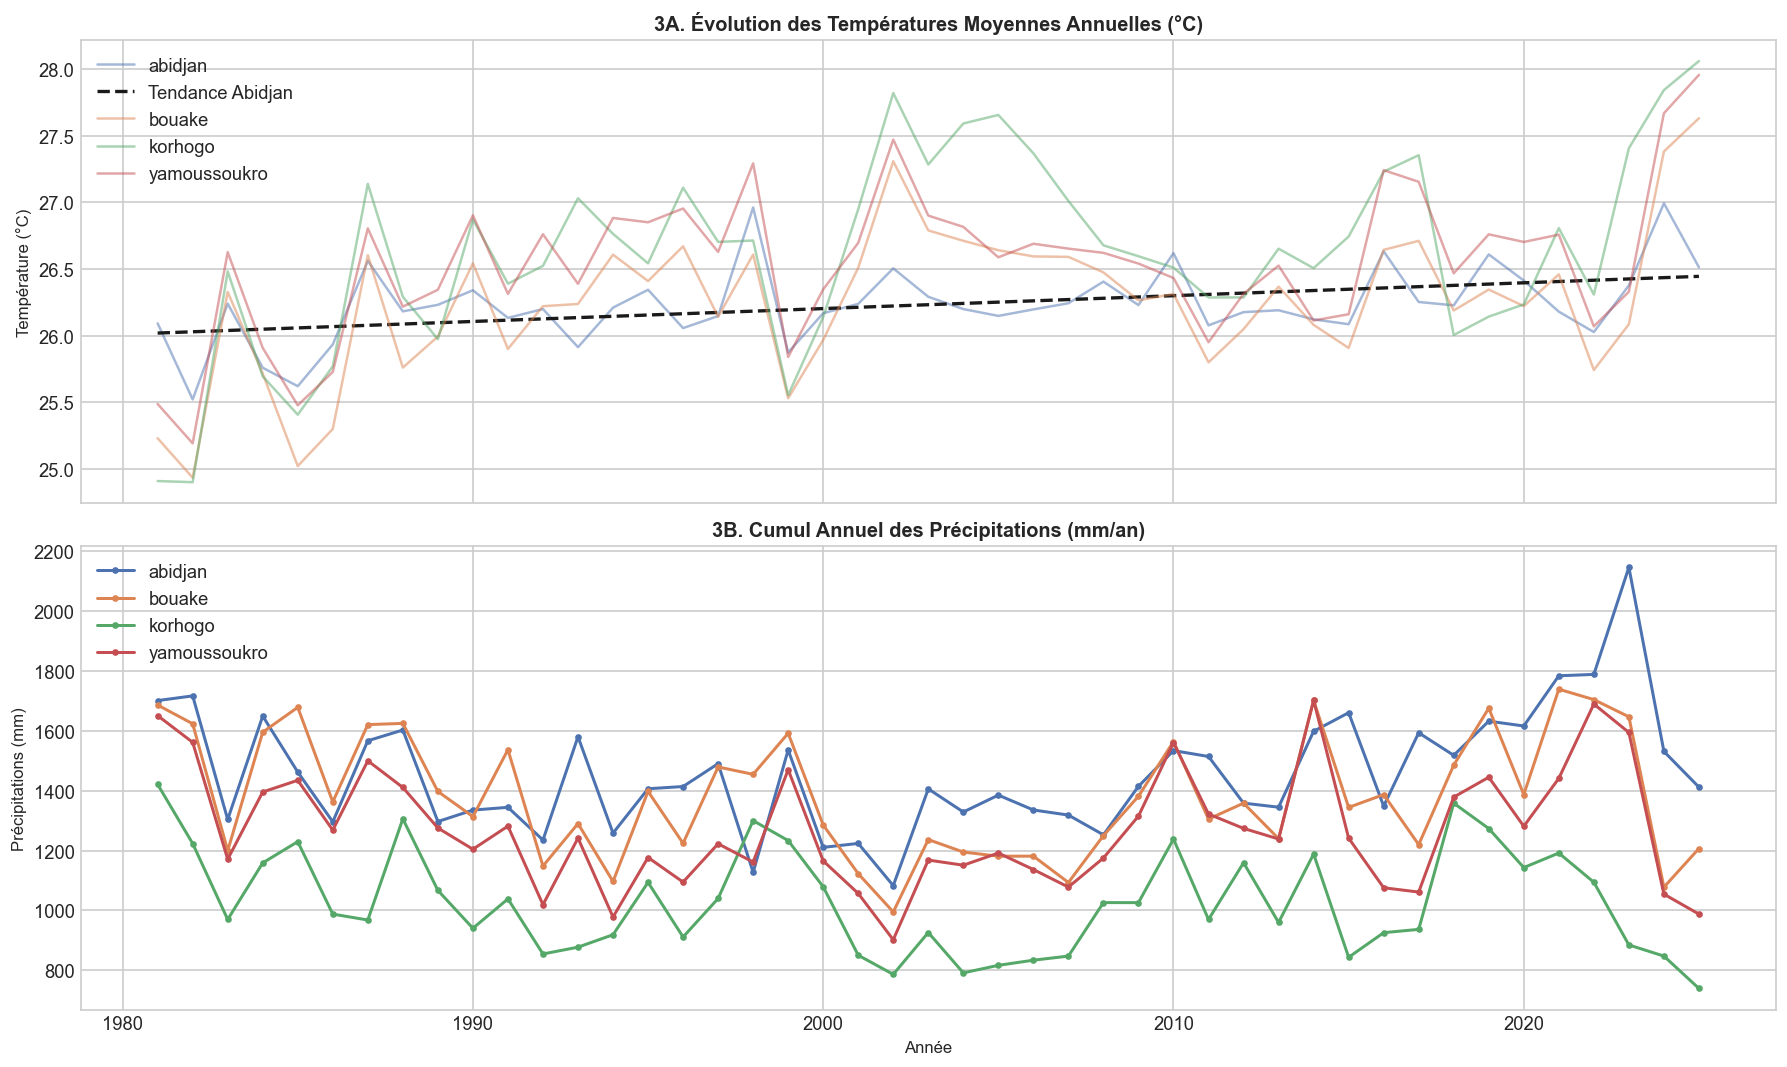

In [99]:
# ==============================================================================
# ÉTAPE 3 : EVOLUTION CLIMATIQUE SUR 44 ANS (1981-2025)
# ==============================================================================

fig, axes = plt.subplots(2, 1, figsize=(15, 9), sharex=True)

# 3A. Évolution de la Température Moyenne Annuelle avec droite de tendance
for site, d in dfs.items():
    annuel = d.groupby("YEAR")["T2M"].mean()
    axes[0].plot(annuel.index, annuel.values, alpha=0.5, label=f"{site}")
    
    # Droite de tendance pour Abidjan (exemple)
    if site == "abidjan":
        p = np.polyfit(annuel.index, annuel.values, 1)
        axes[0].plot(annuel.index, p[0] * annuel.index + p[1], "k--", linewidth=2, label="Tendance Abidjan")

axes[0].set_title("3A. Évolution des Températures Moyennes Annuelles (°C)", fontweight="bold")
axes[0].set_ylabel("Température (°C)")
axes[0].legend(loc="upper left")

# 3B. Cumul Annuel de Pluie par site
pluie_an = df_all.groupby(["YEAR", "site"])["PRECTOTCORR"].sum().unstack()
pluie_an.plot(ax=axes[1], linewidth=1.8, marker="o", markersize=3)
axes[1].set_title("3B. Cumul Annuel des Précipitations (mm/an)", fontweight="bold")
axes[1].set_xlabel("Année")
axes[1].set_ylabel("Précipitations (mm)")
axes[1].legend(loc="upper left")

afficher()

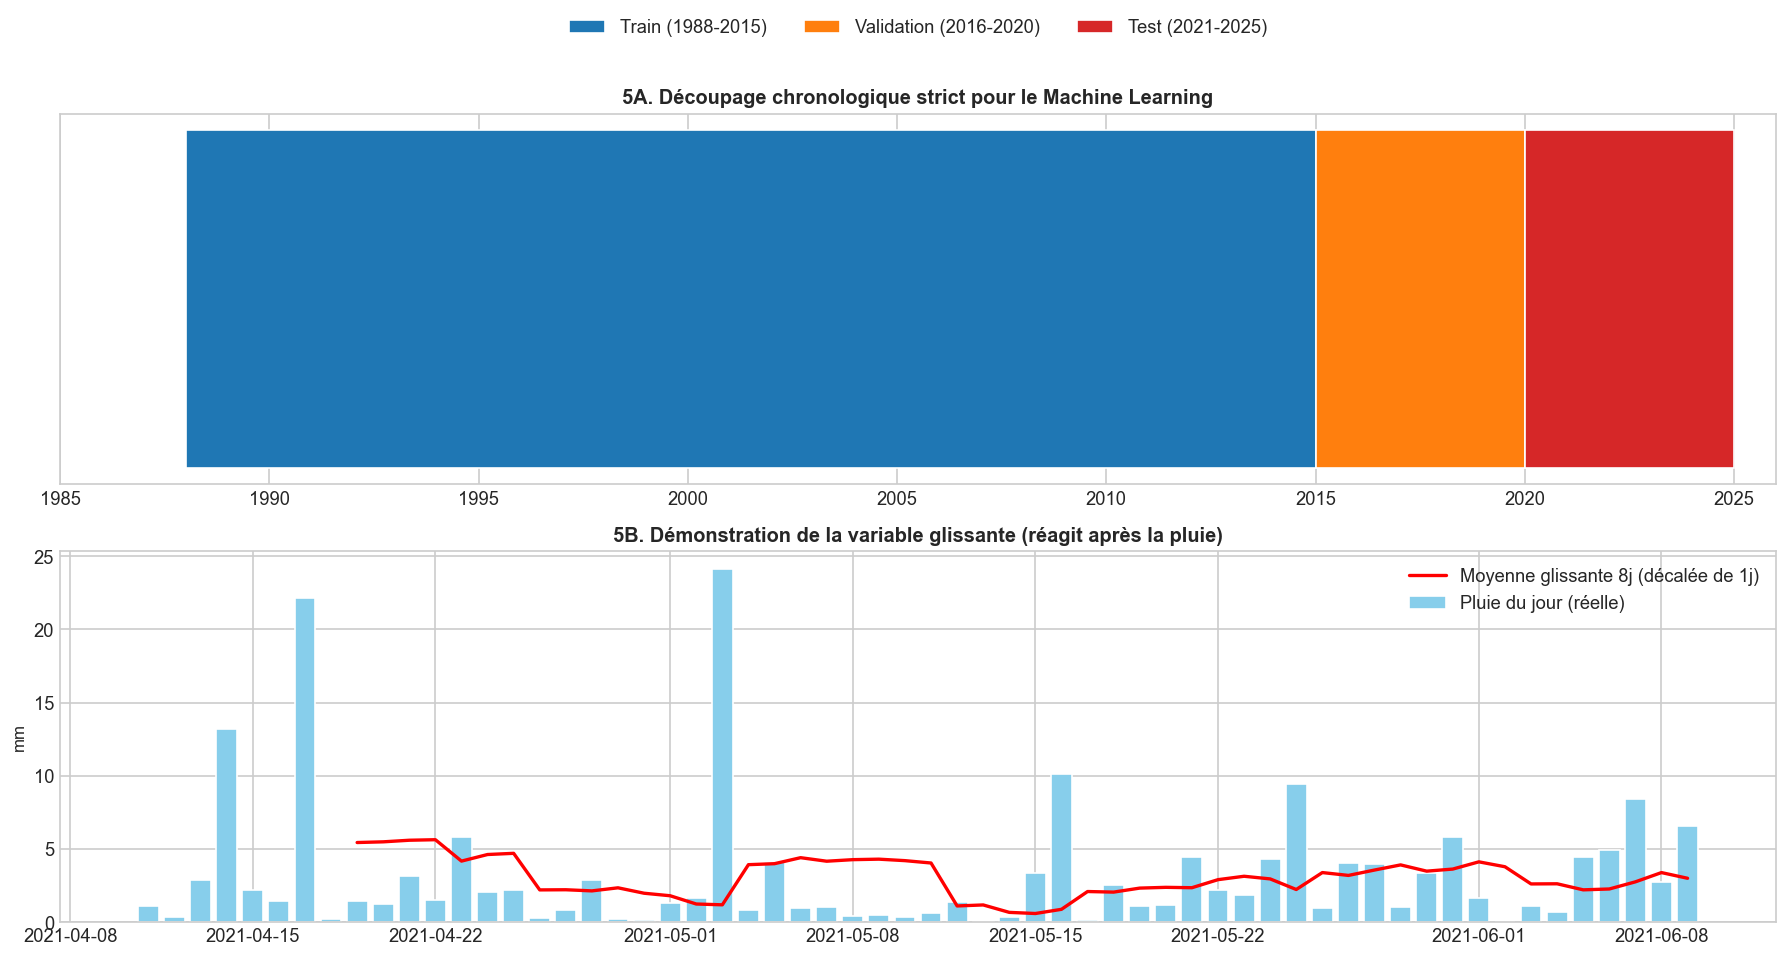

In [101]:
# ==============================================================================
# ÉTAPE 5 : PRÉPARATION ML - CHRONOLOGIE ET VARIABLES GLISSANTES (LAGS)
# ==============================================================================

fig, axes = plt.subplots(2, 1, figsize=(15, 8))

# 5A. Représentation du Découpage Temporel (Train / Valid / Test)
an_min, an_train, an_valid, an_max = 1988, 2015, 2020, 2025
axes[0].barh(0, an_train - an_min, left=an_min, color="#1f77b4", label="Train (1988-2015)")
axes[0].barh(0, an_valid - an_train, left=an_train, color="#ff7f0e", label="Validation (2016-2020)")
axes[0].barh(0, an_max - an_valid, left=an_valid, color="#d62728", label="Test (2021-2025)")
axes[0].set_yticks([])
axes[0].set_xlim(1985, 2026)
axes[0].set_title("5A. Découpage chronologique strict pour le Machine Learning", fontweight="bold")
axes[0].legend(loc="upper center", bbox_to_anchor=(0.5, 1.3), ncol=3)

# 5B. Illustration du fonctionnement d'une variable glissante (Anti-fuite du futur)
# Exemple sur une fenêtre de 60 jours en 2021 à Korhogo
d_ex = dfs["korhogo"][(dfs["korhogo"]["YEAR"] == 2021)].iloc[100:160].copy()
d_ex["PREC_cumul8"] = d_ex["PRECTOTCORR"].shift(1).rolling(8).sum()

axes[1].bar(d_ex["date"], d_ex["PRECTOTCORR"], color="skyblue", label="Pluie du jour (réelle)")
axes[1].plot(d_ex["date"], d_ex["PREC_cumul8"] / 8, color="red", linewidth=2, label="Moyenne glissante 8j (décalée de 1j)")
axes[1].set_title("5B. Démonstration de la variable glissante (réagit après la pluie)", fontweight="bold")
axes[1].set_ylabel("mm")
axes[1].legend()

afficher()

In [103]:
# Contrôle des dates, valeurs manquantes et incohérences physiques.
def controles(d):
    return pd.Series({
        "lignes": len(d),
        "doublons": d.date.duplicated().sum(),
        "jours_manquants": len(pd.date_range(d.date.min(), d.date.max())) - len(d),
        "pluie<0": (d.PRECTOTCORR < 0).sum(),
        "MIN>MAX": (d.T2M_MIN > d.T2M_MAX).sum(),
        "T2M hors MIN-MAX": ((d.T2M < d.T2M_MIN) | (d.T2M > d.T2M_MAX)).sum(),
        "DEW>T2M": (d.T2MDEW > d.T2M).sum(),
        "RH hors 0-100": ((d.RH2M < 0) | (d.RH2M > 100)).sum(),
        "GWET hors 0-1": ((d[GW] < 0) | (d[GW] > 1)).sum().sum(),
        "WS/PS/QV<0": (d[["WS2M", "PS", "QV2M"]] < 0).sum().sum(),
        "ALLSKY>CLRSKY": (d.ALLSKY_SFC_SW_DWN > d.CLRSKY_SFC_SW_DWN).sum()
    })

print(pd.DataFrame({s: controles(d) for s, d in dfs.items()}))
manquants = pd.DataFrame({s: d.isna().mean() * 100 for s, d in dfs.items()})
print("\n% de valeurs manquantes :\n", manquants.loc[manquants.gt(0).any(axis=1)].round(2))

for site, d in dfs.items():
    ecart = d.ALLSKY_SFC_SW_DWN - d.CLRSKY_SFC_SW_DWN
    e = d.loc[ecart > 0].copy()
    print(site, "| ALLSKY>CLRSKY :", len(e),
          "| années :", (e.YEAR.min(), e.YEAR.max()) if len(e) else None,
          "| écart médian/max :", (ecart[ecart > 0].median(), ecart.max()),
          "| mois :", e.date.dt.month.value_counts().sort_index().to_dict())


                  abidjan  bouake  korhogo  yamoussoukro
lignes              16436   16436    16436         16436
doublons                0       0        0             0
jours_manquants         0       0        0             0
pluie<0                 0       0        0             0
MIN>MAX                 0       0        0             0
T2M hors MIN-MAX        0       0        0             0
DEW>T2M                 0       0        0             0
RH hors 0-100           0       0        0             0
GWET hors 0-1           0       0        0             0
WS/PS/QV<0              0       0        0             0
ALLSKY>CLRSKY         227     317      636           148

% de valeurs manquantes :
                    abidjan  bouake  korhogo  yamoussoukro
ALLSKY_SFC_SW_DWN     6.66    6.66     6.66          6.66
CLRSKY_SFC_SW_DWN     6.66    6.66     6.66          6.66
ALLSKY_SFC_LW_DWN    15.55   15.55    15.55         15.55
abidjan | ALLSKY>CLRSKY : 227 | années : (1984, 2000) | 

In [105]:
# Statistiques descriptives communes aux quatre sites.
print(pd.concat(
    {s: d[cols].agg(["mean", "min", "max"]).T for s, d in dfs.items()},
    axis=1
).round(2))


                  abidjan                 bouake                korhogo  \
                     mean     min     max   mean    min     max    mean   
T2M                 26.23   22.17   30.65  26.26  19.21   32.54   26.63   
T2M_MAX             29.65   24.27   37.80  31.39  23.27   40.78   32.92   
T2M_MIN             23.80   17.28   27.06  21.88  12.02   26.94   21.20   
T2MDEW              22.86    9.53   26.14  20.41  -5.65   25.03   17.06   
RH2M                83.01   39.28   94.34  74.28  13.87   95.23   62.59   
QV2M                17.50    7.70   21.23  15.71   2.57   20.30   13.54   
PRECTOTCORR          3.99    0.00  132.25   3.79   0.00  140.68    2.82   
ALLSKY_SFC_SW_DWN   17.00    2.52   24.92  17.21   3.02   26.50   19.19   
CLRSKY_SFC_SW_DWN   22.59   13.04   26.80  22.41  12.90   26.85   22.87   
ALLSKY_SFC_LW_DWN   35.69   29.42   37.81  34.97  27.55   38.10   34.29   
WS2M                 2.43    0.41    4.58   1.76   0.40    4.25    1.94   
PS                 100.53

In [107]:
# Tendances annuelles : calcul unique des p-values et pentes par décennie.
tendances = []
for site, d in dfs.items():
    annuel = d.groupby("YEAR")[VARIABLES_TENDANCE].mean()
    for variable in VARIABLES_TENDANCE:
        r = linregress(annuel.index, annuel[variable])
        tendances.append((site, variable, r.slope * 10, r.pvalue))

tend = pd.DataFrame(tendances, columns=["site", "variable", "pente_decennie", "p"])
print(tend.pivot(index="variable", columns="site",
                 values=["pente_decennie", "p"]).round(3))


            pente_decennie                                   p                 \
site               abidjan bouake korhogo yamoussoukro abidjan bouake korhogo   
variable                                                                        
PRECTOTCORR          0.118 -0.031  -0.066       -0.012   0.059  0.638   0.226   
RH2M                 0.837 -0.384  -0.725       -0.156   0.000  0.311   0.117   
T2M                  0.097  0.196   0.261        0.182   0.002  0.001   0.001   
T2M_MAX             -0.033  0.211   0.339        0.174   0.498  0.025   0.002   
T2M_MIN              0.169  0.163   0.203        0.167   0.000  0.000   0.001   

                          
site        yamoussoukro  
variable                  
PRECTOTCORR        0.850  
RH2M               0.669  
T2M                0.003  
T2M_MAX            0.078  
T2M_MIN            0.000  


Extrêmes 3×IQR :
                    abidjan  bouake  korhogo  yamoussoukro
T2M                      0       0        0             0
T2M_MAX                  0       0        0             0
T2M_MIN                  2     235       83           137
T2MDEW                 193    1494       17          1159
RH2M                   126       0        0            21
QV2M                   115    1036        0           805
PRECTOTCORR            312     264      331           286
ALLSKY_SFC_SW_DWN        1       0        9             1
CLRSKY_SFC_SW_DWN        0       0        0             0
ALLSKY_SFC_LW_DWN      187     707      132           457
WS2M                     0       0        0             0
PS                       0       0        0             0
TS                       0       0        0             0
EVLAND                   0       0        0             0
EVPTRNS                  0       0        0             0
GWETTOP                  0       0        0           

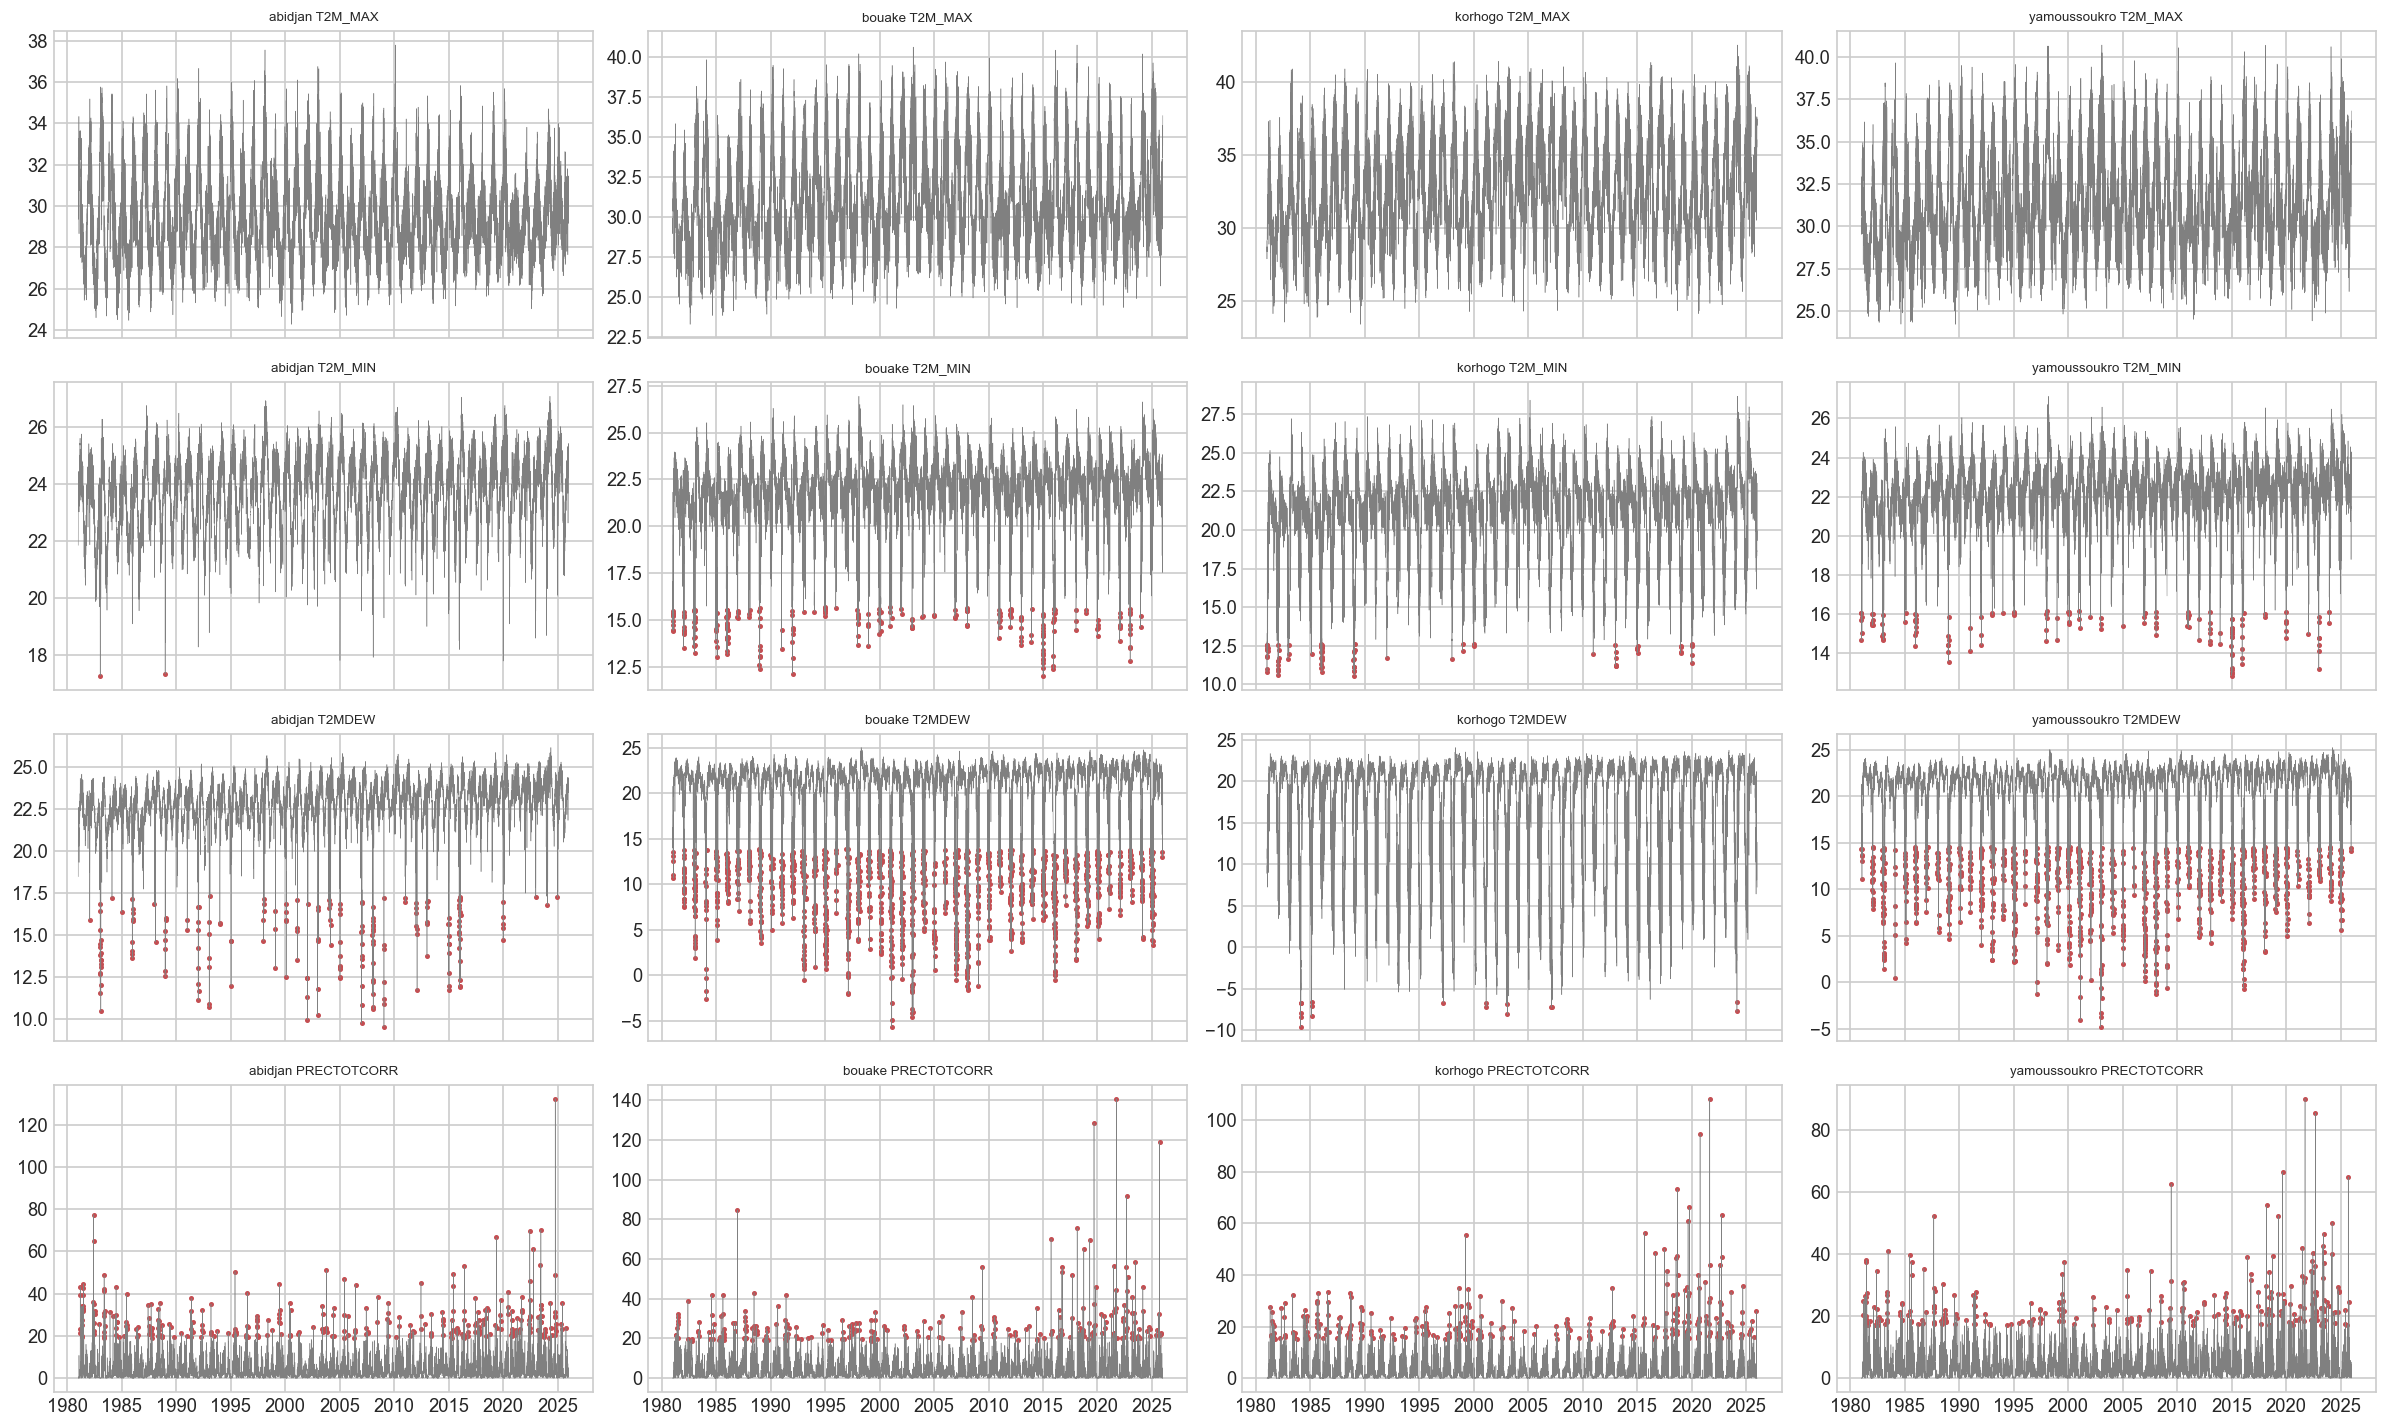


abidjan
       date  T2MDEW  RH2M
2009-01-24    9.53 41.98
2007-01-04    9.74 42.33 
       date  T2M_MAX
2010-02-06    37.80
1998-02-23    37.56 
       date  PRECTOTCORR  GWETTOP
2024-10-13       132.25     0.88
1982-06-01        77.45     0.92

bouake
       date  T2MDEW  RH2M
2001-02-14   -5.65 13.90
2001-02-13   -4.94 14.41 
       date  T2M_MAX
2018-02-16    40.78
2003-02-03    40.65 
       date  PRECTOTCORR  GWETTOP
2021-09-26       140.68     0.90
2019-09-08       128.36     0.91

korhogo
       date  T2MDEW  RH2M
1984-02-06   -9.63  9.96
1984-02-07   -8.49 11.54 
       date  T2M_MAX
2024-03-18    42.55
2024-03-17    41.83 
       date  PRECTOTCORR  GWETTOP
2021-08-26       108.31     0.85
2020-10-05        94.61     0.87

yamoussoukro
       date  T2MDEW  RH2M
2002-12-27   -4.79 14.97
2001-02-14   -4.06 16.20 
       date  T2M_MAX
2003-02-02    40.69
2018-02-16    40.68 
       date  PRECTOTCORR  GWETTOP
2021-09-26        89.88     0.86
2022-09-06        85.32     0.88
abid

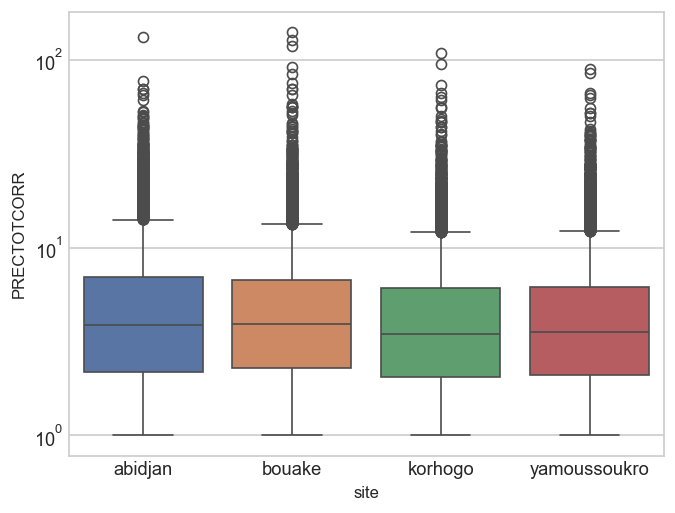

In [109]:
def ext(d, c, k=3):
    q1, q3 = d[c].quantile([.25, .75]); i = q3 - q1
    return d[(d[c] < q1 - k * i) | (d[c] > q3 + k * i)]

print("Extrêmes 3×IQR :\n", pd.DataFrame({s: {c: len(ext(d, c)) for c in cols} for s, d in dfs.items()}))

# Séries avec extrêmes marqués : 4 variables x 4 sites
fig, ax = plt.subplots(4, 4, figsize=(20, 12), sharex=True)
for j, (s, d) in enumerate(dfs.items()):
    for i, c in enumerate(["T2M_MAX", "T2M_MIN", "T2MDEW", "PRECTOTCORR"]):
        o = ext(d, c); ax[i, j].plot(d.date, d[c], lw=.3, c="grey"); ax[i, j].scatter(o.date, o[c], c="r", s=4)
        ax[i, j].set_title(f"{s} {c}", fontsize=8)
afficher()

# Dates des extrêmes et pluie max
for s, d in dfs.items():
    print(f"\n{s}\n", d.nsmallest(2, "T2MDEW")[["date", "T2MDEW", "RH2M"]].to_string(index=False),
          "\n", d.nlargest(2, "T2M_MAX")[["date", "T2M_MAX"]].to_string(index=False),
          "\n", d.nlargest(2, "PRECTOTCORR")[["date", "PRECTOTCORR", "GWETTOP"]].to_string(index=False))

# Pluie : % de jours secs, distribution des jours pluvieux
for s, d in dfs.items():
    print(s, "| 0 mm :", f"{(d.PRECTOTCORR == 0).mean():.1%}", "| >= 1 mm :", f"{(d.PRECTOTCORR >= 1).mean():.1%}")
sns.boxplot(data=df_all[df_all.PRECTOTCORR >= 1], x="site", y="PRECTOTCORR", hue="site", legend=False).set_yscale("log"); plt.show()

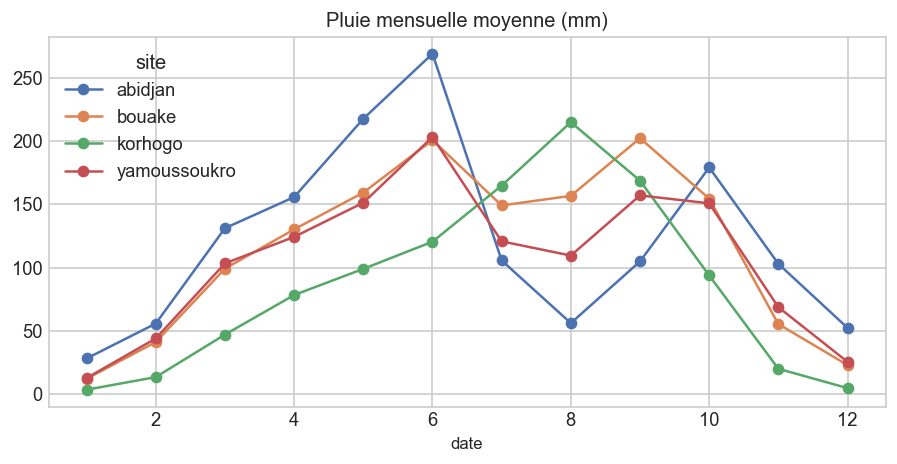

site  abidjan  bouake  korhogo  yamoussoukro
date                                        
1        28.0    12.0      3.0          13.0
2        56.0    41.0     13.0          44.0
3       131.0    99.0     47.0         103.0
4       156.0   130.0     78.0         124.0
5       218.0   159.0     99.0         151.0
6       269.0   201.0    120.0         203.0
7       106.0   149.0    165.0         121.0
8        56.0   157.0    215.0         110.0
9       105.0   202.0    169.0         157.0
10      179.0   155.0     94.0         151.0
11      103.0    55.0     20.0          69.0
12       52.0    23.0      5.0          25.0
{'abidjan': 1459.0, 'bouake': 1384.0, 'korhogo': 1028.0, 'yamoussoukro': 1271.0}
abidjan | sèches : {2002: 1083.0, 1998: 1127.0, 2000: 1211.0, 2001: 1224.0, 1992: 1235.0} | humides : {2023: 2145.0, 2022: 1788.0, 2021: 1783.0, 1982: 1716.0, 1981: 1700.0}
bouake | sèches : {2002: 995.0, 2024: 1078.0, 2007: 1093.0, 1994: 1097.0, 2001: 1123.0} | humides : {2021: 1738.0, 2

In [111]:
pm = df_all.groupby(["site", "YEAR", df_all.date.dt.month]).PRECTOTCORR.sum().groupby(level=[0, 2]).mean().unstack(0)
pm.plot(marker="o", figsize=(9, 4), title="Pluie mensuelle moyenne (mm)"); plt.show()
print(pm.round(0))

pa = df_all.groupby(["site", "YEAR"]).PRECTOTCORR.sum().unstack(0)
print(pa.mean().round(0).to_dict())
for s in pa: print(s, "| sèches :", pa[s].nsmallest(5).round(0).to_dict(), "| humides :", pa[s].nlargest(5).round(0).to_dict())
print("Rang (1 = plus sèche) :\n", pa.rank().loc[[1998, 2002, 2023, 2024, 2025]])

                       abidjan       bouake      korhogo yamoussoukro
GWETROOT/GWETPROF  1.00 → 1.00  0.99 → 0.99  0.95 → 0.96  0.99 → 0.99
T2MDEW/QV2M        0.99 → 0.99  0.99 → 0.98  0.99 → 0.97  0.99 → 0.98
T2M/TS             0.98 → 0.95  0.99 → 0.98  0.99 → 0.98  0.98 → 0.98
GWETTOP/GWETROOT   0.96 → 0.93  0.95 → 0.92  0.90 → 0.83  0.94 → 0.92


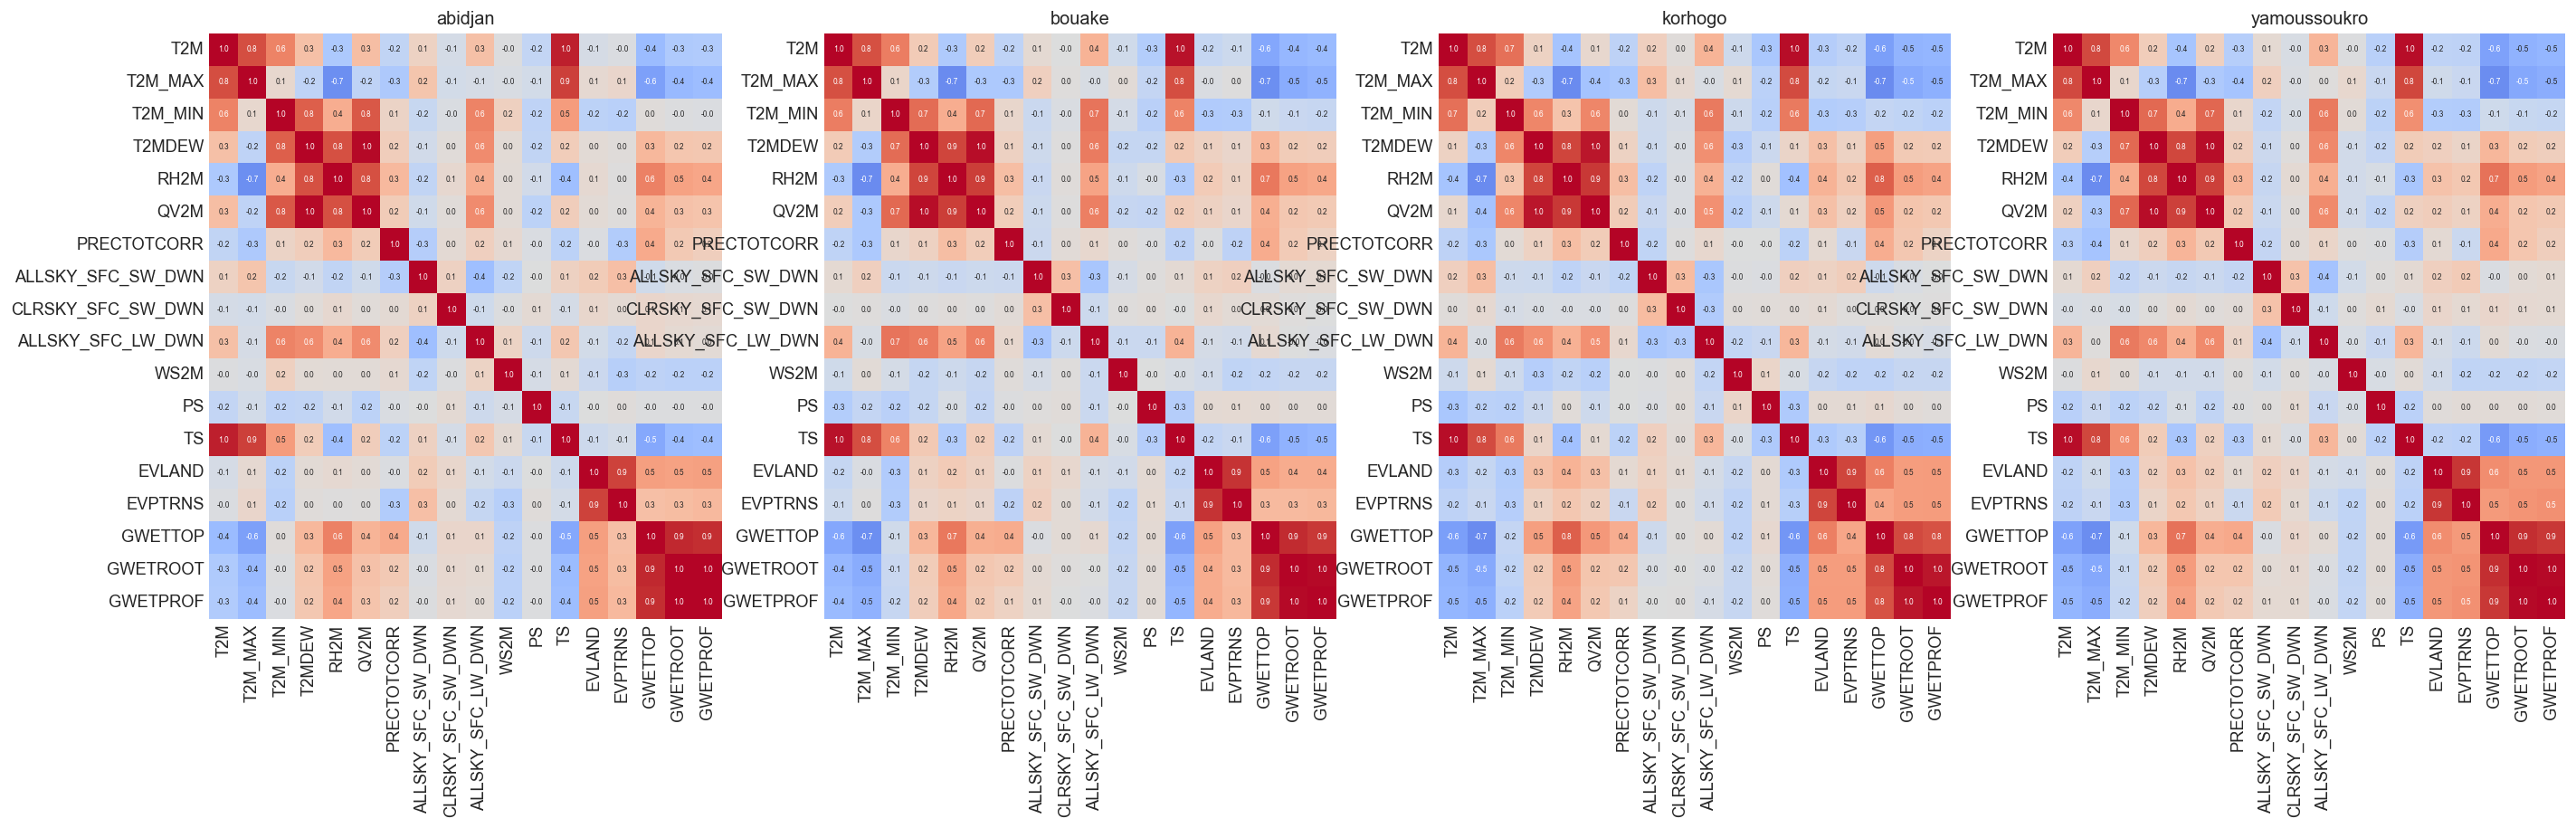

Pluie :
               abidjan  bouake  korhogo  yamoussoukro
abidjan          1.00    0.50     0.17          0.65
bouake           0.50    1.00     0.49          0.89
korhogo          0.17    0.49     1.00          0.38
yamoussoukro     0.65    0.89     0.38          1.00


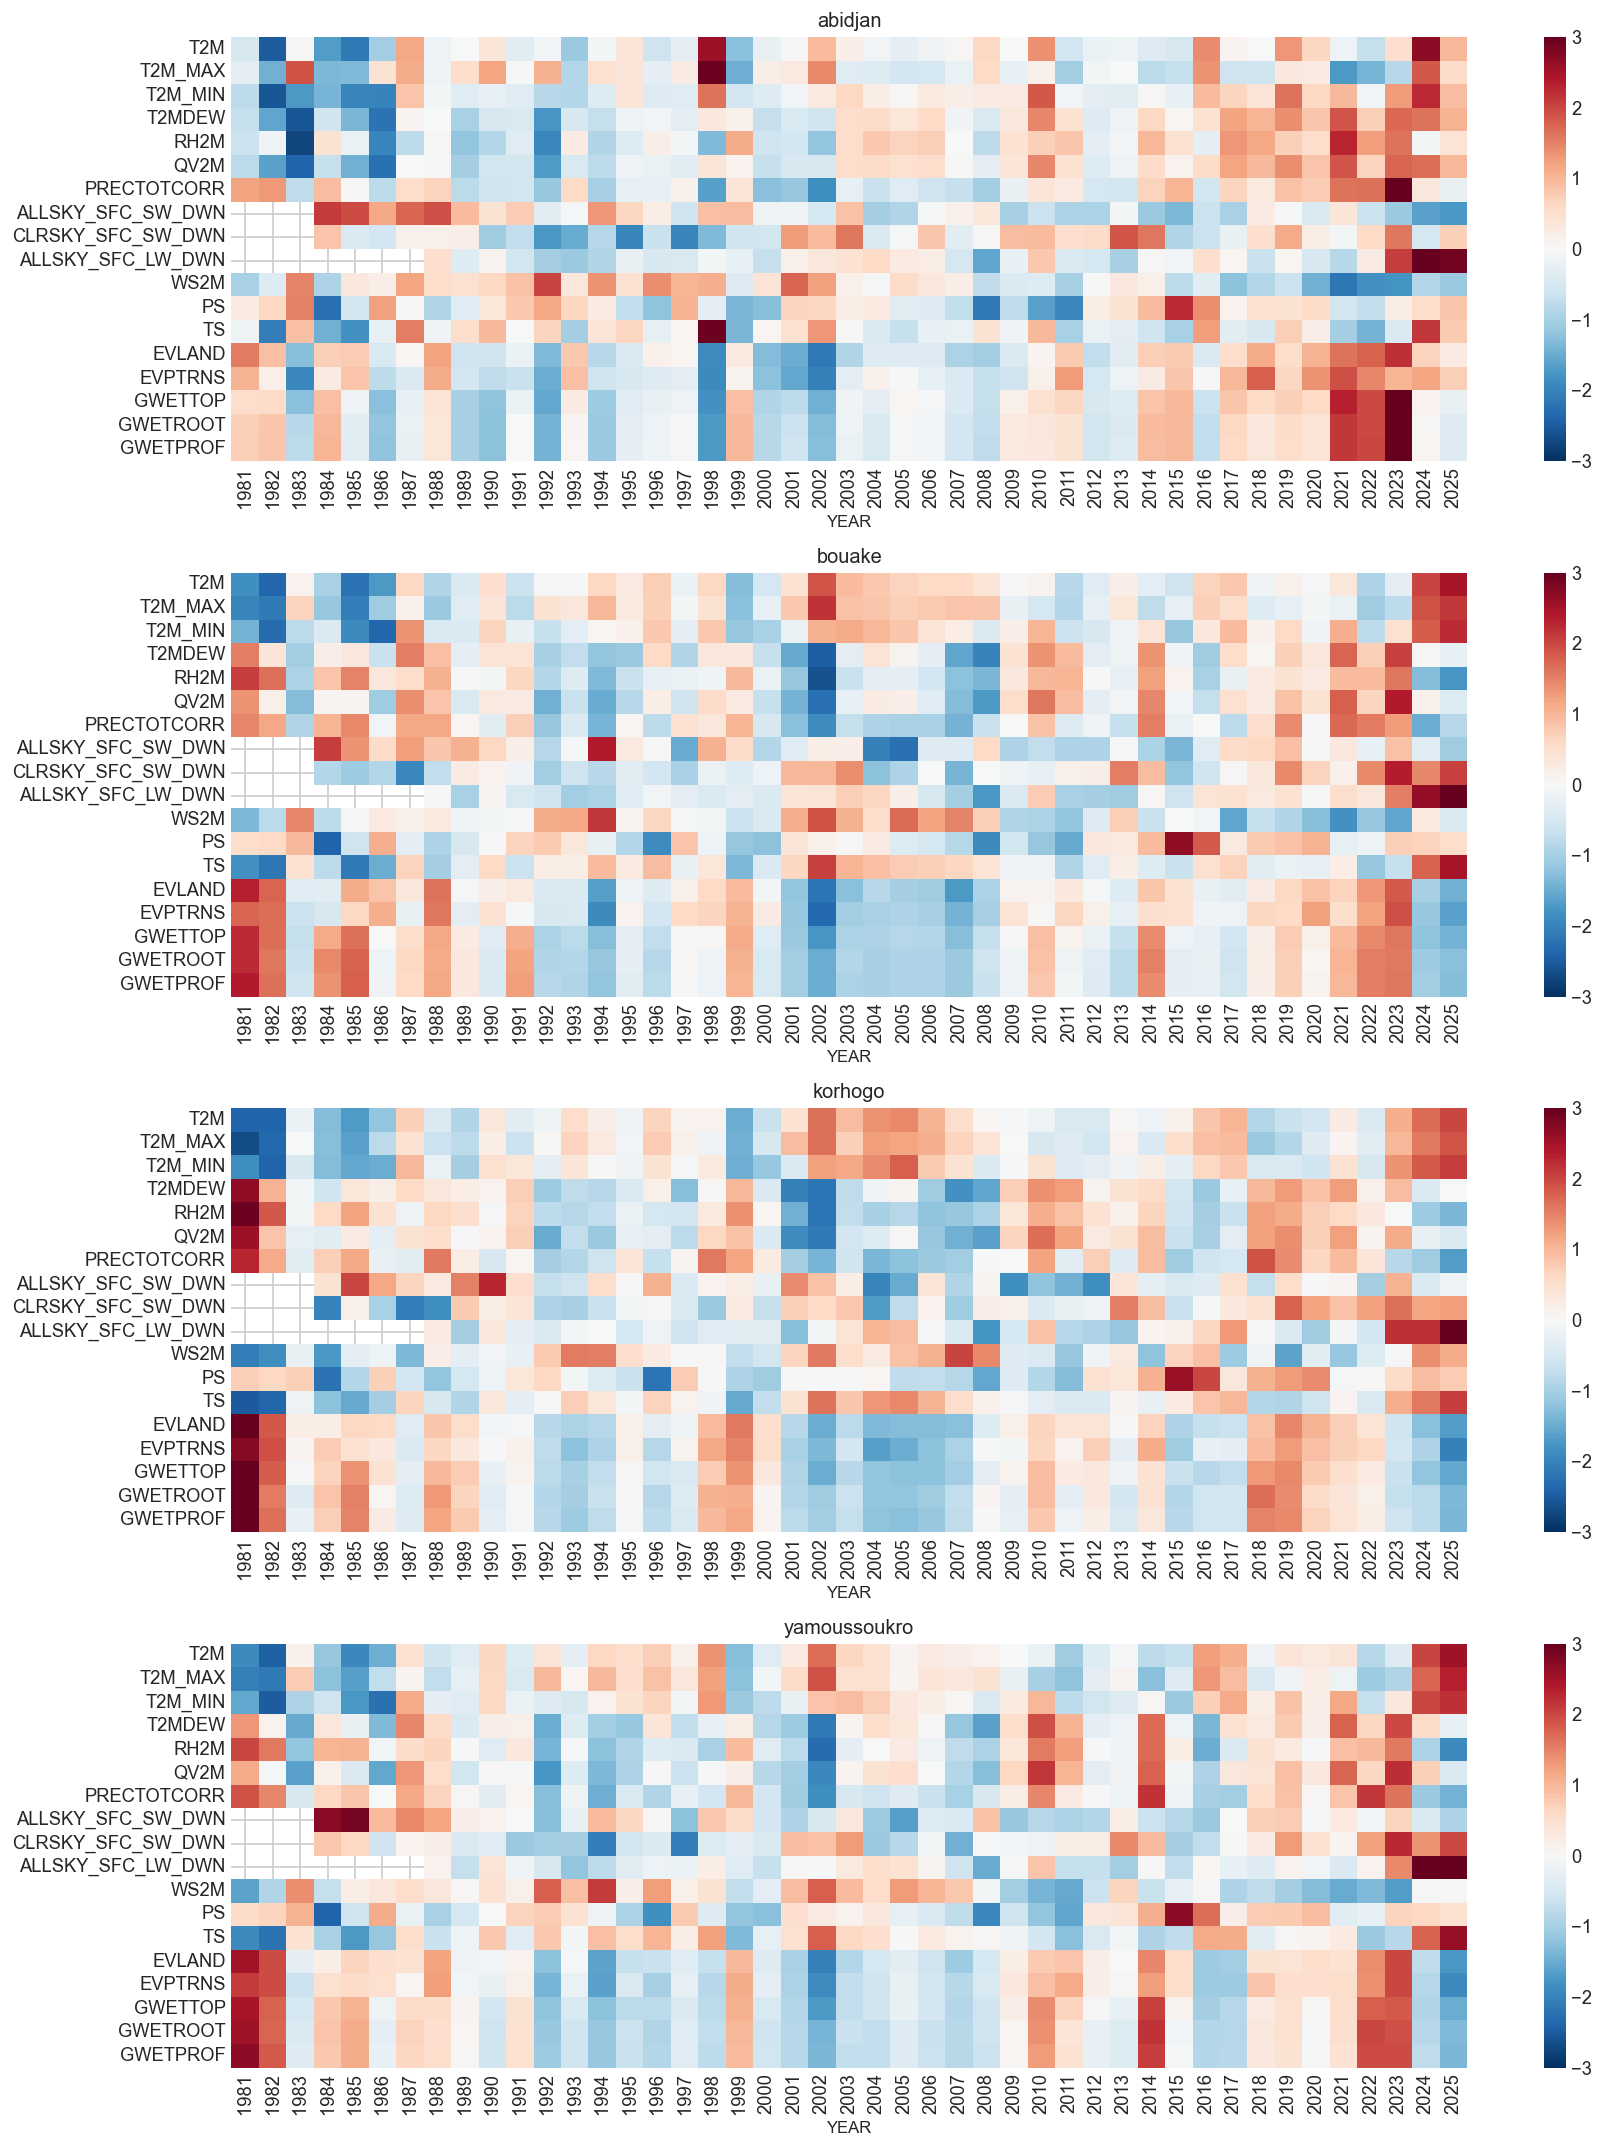

In [113]:
anom = {s: d[cols] - d.groupby("DOY")[cols].transform("mean") for s, d in dfs.items()}
paires = [("GWETROOT", "GWETPROF"), ("T2MDEW", "QV2M"), ("T2M", "TS"), ("GWETTOP", "GWETROOT")]
print(pd.DataFrame({s: {f"{a}/{b}": f"{dfs[s][a].corr(dfs[s][b]):.2f} → {anom[s][a].corr(anom[s][b]):.2f}"
                        for a, b in paires} for s in dfs}))   # brut → anomalies

fig, ax = plt.subplots(1, 4, figsize=(28, 7))
for a, (s, x) in zip(ax, anom.items()):
    sns.heatmap(x.corr(), cmap="coolwarm", vmin=-1, vmax=1, annot=True, fmt=".1f", annot_kws={"size": 5}, cbar=False, ax=a); a.set_title(s)
plt.show()

print("Pluie :\n", pd.DataFrame({s: {t: round(dfs[s].PRECTOTCORR.corr(dfs[t].PRECTOTCORR), 2) for t in dfs} for s in dfs}))

# Heatmap annuelle standardisée (4 sites)
fig, ax = plt.subplots(4, 1, figsize=(15, 18))
for a, (s, d) in zip(ax, dfs.items()):
    m = d.groupby("YEAR")[cols].mean(); sns.heatmap(((m - m.mean()) / m.std()).T, cmap="RdBu_r", center=0, vmin=-3, vmax=3, ax=a); a.set_title(s)
afficher()

                    abidjan  bouake  korhogo  yamoussoukro
pluie_mm             1458.8  1383.9   1028.5        1271.1
bilan_mm              211.8   126.5     46.7          88.0
jours_stress           68.3    60.3     64.7          73.0
jours_saison_seche     45.4    67.4    118.0          62.7
serie_seche_max        22.1    31.7     47.3          29.0
jours_pluvieux        254.1   250.0    201.5         248.3
cv_pluie_mensuelle      0.7     0.7      0.9           0.7
      abidjan  bouake  korhogo  yamoussoukro
YEAR                                        
1998      154      65       80            91
2002      157     164      141           186
2023        0       5       72             9
2024       28      63      126            79


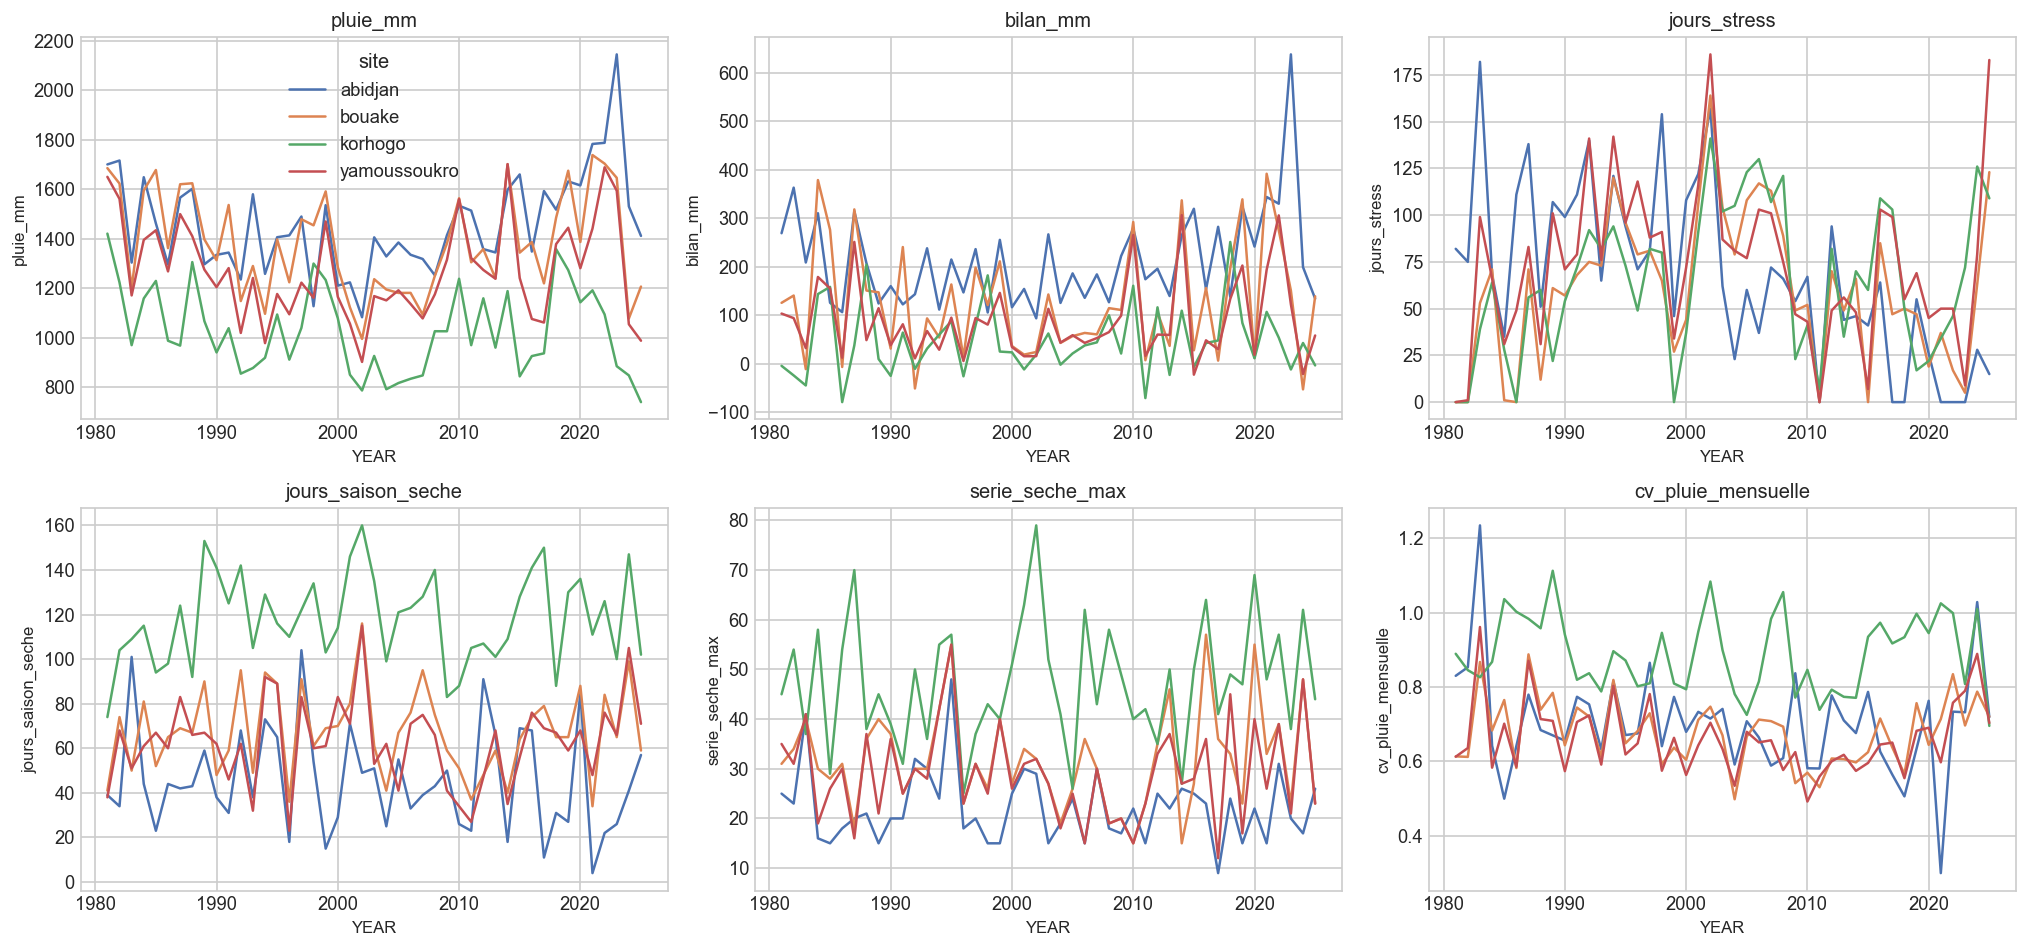

In [114]:
# PROVISOIRE : à valider avec l'équipe
SEUIL_SEC, FEN, SEUIL_FEN, PCT_STRESS = 1, 30, 30, 0.20   # mm/j ; jours ; mm ; percentile GWETROOT

def serie_max(m):                       # plus longue suite de True
    best = cur = 0
    for v in m: cur = cur + 1 if v else 0; best = max(best, cur)
    return best

def indicateurs(d):
    d = d.sort_values("date")
    x = pd.DataFrame({
        "bilan": d.PRECTOTCORR - d.EVLAND,                                   # approximation : EVLAND n'est pas l'ETP
        "stress": d.GWETROOT < d.GWETROOT.quantile(PCT_STRESS),              # seuil relatif au site
        "seche": d.PRECTOTCORR.rolling(FEN).sum() < SEUIL_FEN,               # saison sèche
        "jour_sec": d.PRECTOTCORR < SEUIL_SEC, "pluie": d.PRECTOTCORR, "YEAR": d.YEAR, "mois": d.date.dt.month})
    g = x.groupby("YEAR"); pm = x.groupby(["YEAR", "mois"]).pluie.sum().groupby(level=0)
    return pd.DataFrame({"pluie_mm": g.pluie.sum(), "bilan_mm": g.bilan.sum(), "jours_stress": g.stress.sum(),
                         "jours_saison_seche": g.seche.sum(), "serie_seche_max": g.jour_sec.apply(serie_max),
                         "jours_pluvieux": g.jour_sec.apply(lambda s: (~s).sum()), "cv_pluie_mensuelle": pm.std() / pm.mean()})

ind = {s: indicateurs(d) for s, d in dfs.items()}
print(pd.concat({s: t.mean() for s, t in ind.items()}, axis=1).round(1))

# Contrôle : 2002 doit ressortir (Abidjan, Bouaké, Yamoussoukro) ; 2023 faible à Abidjan
print(pd.DataFrame({s: t.jours_stress for s, t in ind.items()}).loc[[1998, 2002, 2023, 2024]])

# Visualisation
ia = pd.concat(ind, names=["site", "YEAR"]).reset_index()
fig, ax = plt.subplots(2, 3, figsize=(17, 8))
for a, c in zip(ax.ravel(), ["pluie_mm", "bilan_mm", "jours_stress", "jours_saison_seche", "serie_seche_max", "cv_pluie_mensuelle"]):
    sns.lineplot(data=ia, x="YEAR", y=c, hue="site", ax=a, legend=a is ax[0, 0]); a.set_title(c)
afficher()

split         test  train  valid
site                            
abidjan       1826  10227   1827
bouake        1826  10227   1827
korhogo       1826  10227   1827
yamoussoukro  1826  10227   1827
NaN restants :
 Series([], dtype: int64)
        T2M  PRECTOTCORR
split                   
test   0.21         0.10
train  0.00        -0.00
valid  0.06         0.07


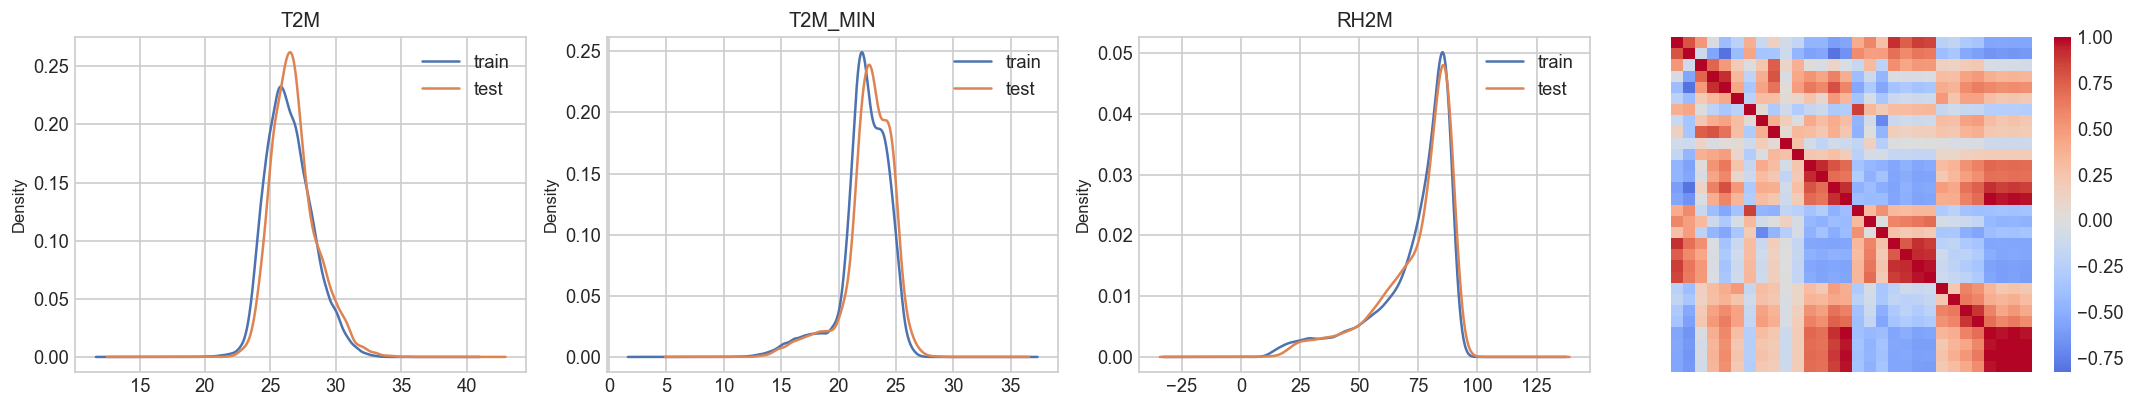

In [117]:
# PROVISOIRE : dépend de la cible (D2) et du pas de temps (D4)
DEBUT, FIN_TRAIN, FIN_VALID = 1988, 2015, 2020
A_RETIRER = ["GWETPROF", "QV2M", "TS"]                                   # décision DS1, même liste sur 4 sites

t = df_all.sort_values(["site", "date"]).reset_index(drop=True).drop(columns=A_RETIRER)
t["nebulosite"] = (t.ALLSKY_SFC_SW_DWN / t.CLRSKY_SFC_SW_DWN.replace(0, np.nan)).clip(upper=1)   # plafonné, aucune ligne supprimée
t["mois"] = t.date.dt.month
t["sin_doy"], t["cos_doy"] = np.sin(2 * np.pi * t.DOY / 365.25), np.cos(2 * np.pi * t.DOY / 365.25)

g = t.groupby("site")                                                    # TOUJOURS par site, passé strict (shift)
for c in ["T2M", "PRECTOTCORR", "GWETROOT"]:
    t[f"{c}_lag1"], t[f"{c}_lag7"] = g[c].shift(1), g[c].shift(7)
    for f in (8, 16):
        t[f"{c}_roll{f}"] = g[c].transform(lambda s: s.shift(1).rolling(f).mean())

t = t[t.YEAR >= DEBUT].copy()                                            # coupe après les retards
t["split"] = np.select([t.YEAR <= FIN_TRAIN, t.YEAR <= FIN_VALID], ["train", "valid"], "test")

# Normalisation : moyenne et écart-type du TRAIN uniquement
num = [c for c in t.columns if c not in ["site", "date", "split", "YEAR", "DOY", "mois"]]
tr = t.split == "train"
tn = t.copy(); tn[num] = (t[num] - t.loc[tr, num].mean()) / t.loc[tr, num].std()

print(t.groupby(["site", "split"]).size().unstack())
print("NaN restants :\n", t.isna().sum()[lambda s: s > 0])
print(tn.groupby("split")[["T2M", "PRECTOTCORR"]].mean().round(2))      # train ≈ 0, test ≠ 0 (réchauffement)

# Visualisations : dérive train/test et corrélations
fig, ax = plt.subplots(1, 4, figsize=(18, 3.5))
for a, c in zip(ax[:3], ["T2M", "T2M_MIN", "RH2M"]):
    for n in ["train", "test"]: t.loc[t.split == n, c].plot(kind="kde", ax=a, label=n)
    a.set_title(c); a.legend()
sns.heatmap(t[num].corr(), cmap="coolwarm", center=0, ax=ax[3], xticklabels=False, yticklabels=False)
afficher()

os.makedirs("data/processed", exist_ok=True)
t.to_parquet("data/processed/table_entrainement_provisoire.parquet", index=False)

### Préparation des données NASA POWER

**Projet : NASA SPACE — Rotations culturales résilientes**

Ce notebook présente l'exploration et le prétraitement des données climatiques historiques NASA POWER (1981–2025) pour quatre villes de Côte d'Ivoire : Abidjan, Bouaké, Korhogo et Yamoussoukro.

**Travail réalisé :**
- Chargement et harmonisation des données climatiques des quatre sites.
- Conversion des valeurs manquantes (`-999`) en `NaN` et normalisation des dates.
- Vérification de la qualité des données : doublons, valeurs manquantes et incohérences physiques.
- Analyse exploratoire des principales variables climatiques (température, précipitations, humidité, rayonnement solaire).
- Étude des variations saisonnières, des tendances climatiques et de premiers indicateurs liés aux conditions agricoles.

**À retenir pour la phase Machine Learning :**

Les données sont organisées par site dans le dictionnaire `dfs` et regroupées dans `df_all`. La colonne `date` permet leur exploitation temporelle.

Les valeurs manquantes doivent être traitées selon les besoins des modèles, sans introduire de biais temporel. Les variables climatiques peuvent servir à construire des indicateurs agronomiques supplémentaires (cumuls de pluie, périodes sèches, stress thermique, etc.).

**Limites actuelles :** ce notebook constitue une base d'analyse climatique. Il ne représente pas encore un dataset ML final intégrant les données SoilGrids et AppEEARS. La définition de la variable cible, la fusion des sources et la séparation temporelle entraînement/test restent à réaliser.

**Conclusion :** ce travail fournit une première base climatique structurée et analysée, destinée à faciliter les prochaines étapes de feature engineering et de modélisation des rotations culturales résilientes.